# P27: real-TESS validation set scoping

Companion notebook to `README.md`. Running it top to bottom regenerates every figure in `figures/` from the small tables in `data/` and the draft manifest `datasets/proposed/p27_validation_draft.csv`. The catalogue queries live in `tools/validation_set/` (network; cached under the gitignored `data/p27_cache/`).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
REPORT = REPO / "reports" / "2026-11-12_validation-set-scoping"
FIG, DATA = REPORT / "figures", REPORT / "data"
FIG.mkdir(exist_ok=True)
sys.path.insert(0, str(REPO / "tools" / "validation_set"))
from build_rotators import gyro_mh08, bv_from_bprp, CLUSTERS
rot = pd.read_csv(DATA / "rotators_all.csv")
man = pd.read_csv(REPO / "datasets" / "proposed" / "p27_validation_draft.csv")
dev = pd.read_csv(REPO / "datasets" / "dev_medium.csv")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "axes.grid": True, "grid.alpha": 0.3})
print(len(rot), "literature rotators;", len(man), "stars in draft manifest")

3363 literature rotators; 480 stars in draft manifest


## 1. Period-colour diagrams per cluster, with the gyrochronology expectation

Grey line: Mamajek & Hillenbrand (2008) at the cluster age (valid for 0.5 < (B-V)0 < 1.4; dashed lines at x0.6 and x1.6 bound the `slow_seq` flag). Red crosses: `too_slow` (P >= 1.6 P_gyro: likely 2P alias, blend or non-member). Orange: `fast` (unconverged, expected in young clusters). Hollow: outside the gyro calibration range.

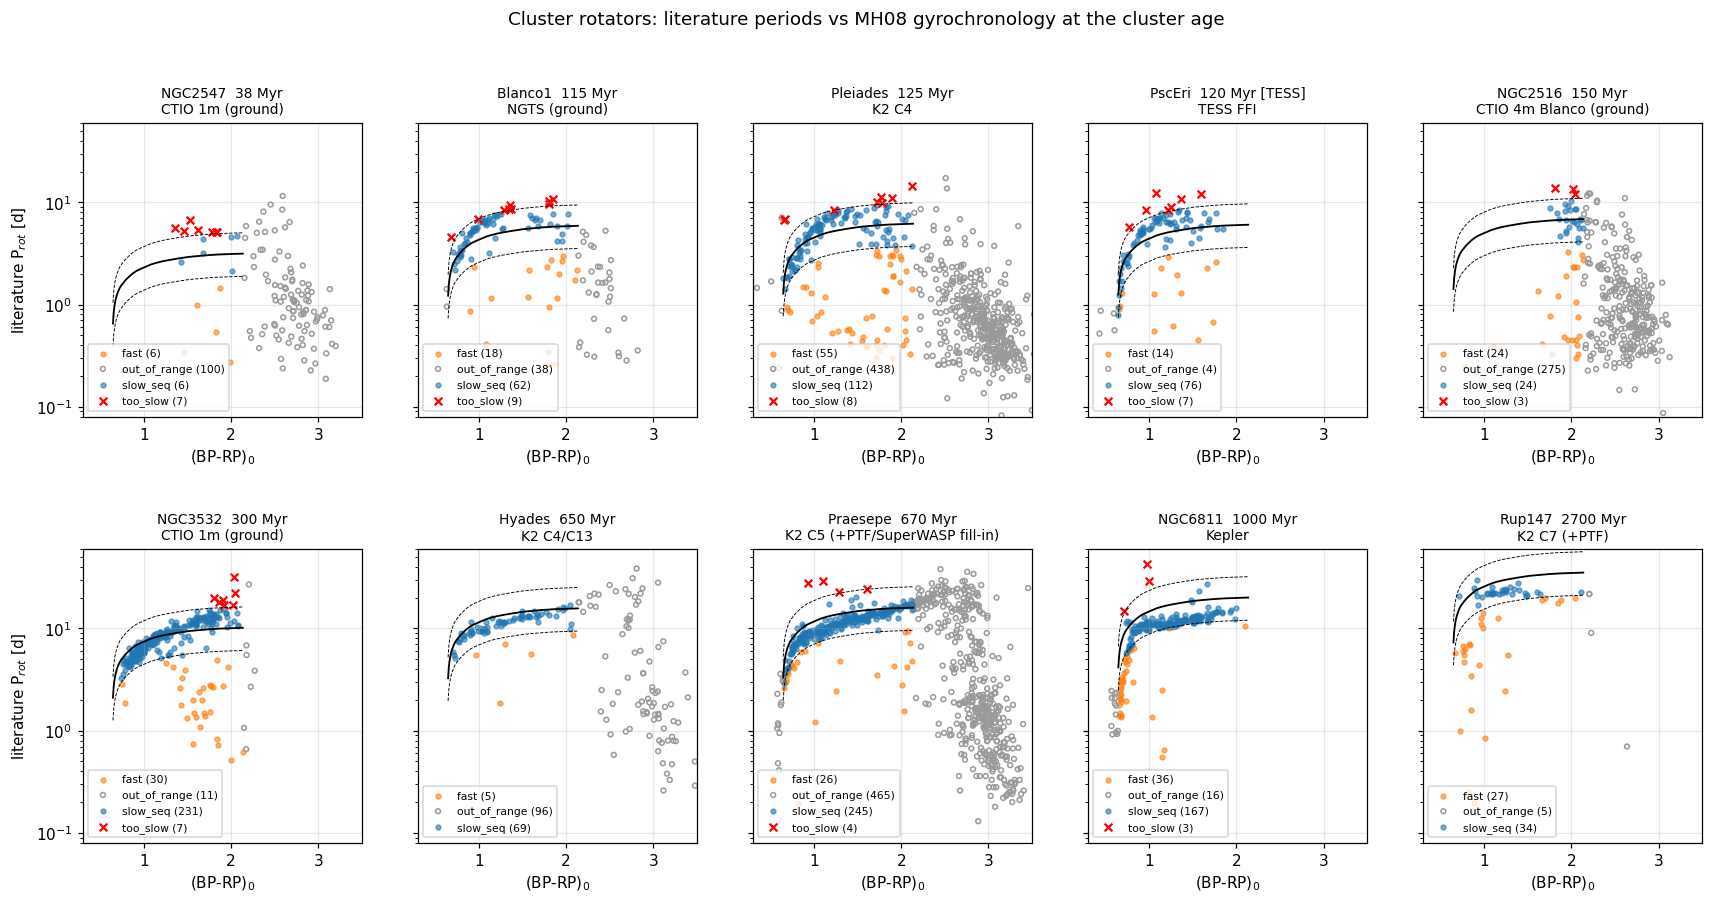

gyro_flag  fast  out_of_range  slow_seq  too_slow
cluster                                          
Blanco1      18            38        62         9
Hyades        5            96        69         0
NGC2516      24           275        24         3
NGC2547       6           100         6         7
NGC3532      30            11       231         7
NGC6811      36            16       167         3
Pleiades     55           438       112         8
Praesepe     26           465       245         4
PscEri       14             4        76         7
Rup147       27             5        34         0


In [2]:
order = ["NGC2547", "Blanco1", "Pleiades", "PscEri", "NGC2516", "NGC3532", "Hyades", "Praesepe", "NGC6811", "Rup147"]
fig, axes = plt.subplots(2, 5, figsize=(19, 8.5), sharey=True, gridspec_kw={"hspace": 0.45})
colors = {"slow_seq": "C0", "fast": "C1", "too_slow": "red", "out_of_range": "0.6"}
for ax, cl in zip(axes.flat, order):
    d = rot[rot.cluster == cl]
    for f, g in d.groupby("gyro_flag"):
        kw = dict(marker="x", s=25) if f == "too_slow" else dict(s=10, alpha=0.6)
        if f == "out_of_range":
            kw = dict(s=10, facecolors="none", edgecolors="0.6")
            ax.scatter(g.bprp0, g.prot, label=f"{f} ({len(g)})", **kw)
        else:
            ax.scatter(g.bprp0, g.prot, c=colors[f], label=f"{f} ({len(g)})", **kw)
    x = np.linspace(0.6, 2.2, 200)
    pg = gyro_mh08(bv_from_bprp(x), np.full_like(x, CLUSTERS[cl]["age"]))
    ax.plot(x, pg, "k-", lw=1.2); ax.plot(x, 0.6 * pg, "k--", lw=0.6); ax.plot(x, 1.6 * pg, "k--", lw=0.6)
    ax.set_yscale("log"); ax.set_ylim(0.08, 60); ax.set_xlim(0.3, 3.5)
    tag = " [TESS]" if "TESS" in CLUSTERS[cl]["dataset"] else ""
    ax.set_title(f"{cl}  {CLUSTERS[cl]['age']} Myr{tag}\n{CLUSTERS[cl]['dataset']}", fontsize=9)
    ax.legend(fontsize=7, loc="lower left")
    ax.set_xlabel("(BP-RP)$_0$")
for ax in axes[:, 0]:
    ax.set_ylabel("literature P$_{rot}$ [d]")
fig.suptitle("Cluster rotators: literature periods vs MH08 gyrochronology at the cluster age", y=1.0)
fig.savefig(FIG / "period_color_clusters.png"); plt.show()
print(rot[rot.cluster != "Kepler-field"].groupby(["cluster", "gyro_flag"]).size().unstack(fill_value=0))

## 2. Provenance: literature periods by method and data set

Counts over all literature rotators with a TIC match (left) and over the draft manifest's rotators (right).

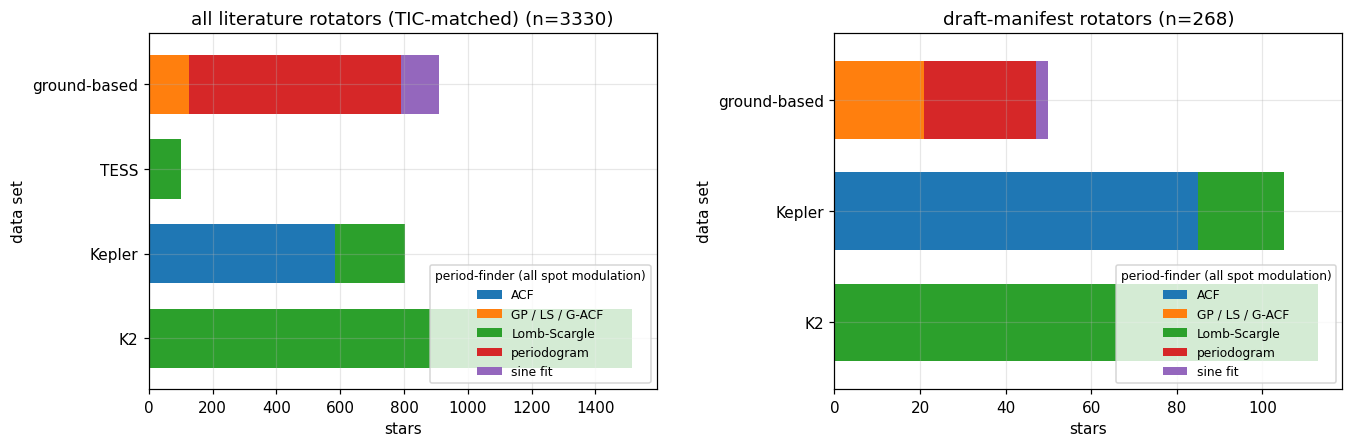

period_dataset  ASAS (ground)  CTIO 1m (ground)  CTIO 4m Blanco (ground)  \
cluster                                                                    
Blanco1                     0                 0                        0   
Hyades                     26                 0                        0   
Kepler-field                0                 0                        0   
NGC2516                     0                 0                      326   
NGC2547                     0               119                        0   
NGC3532                     0               279                        0   
NGC6811                     0                 0                        0   
Pleiades                    0                 0                        0   
Praesepe                    0                 0                        0   
PscEri                      0                 0                        0   
Rup147                      0                 0                        0   

period_data

In [3]:
def short_method(s):
    s = str(s)
    for k in ["GP", "ACF", "Lomb-Scargle", "least-squares", "periodogram"]:
        if k in s:
            return {"GP": "GP / LS / G-ACF", "least-squares": "sine fit"}.get(k, k)
    return s
def ds_group(s):
    s = str(s)
    if "TESS" in s: return "TESS"
    if "K2" in s: return "K2"
    if "Kepler" in s: return "Kepler"
    return "ground-based"
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"wspace": 0.35})
for ax, d, ttl in [(axes[0], rot[rot.tic.notna()], "all literature rotators (TIC-matched)"),
                   (axes[1], man[man.label == "rotator"], "draft-manifest rotators")]:
    t = pd.crosstab(d.period_dataset.map(ds_group), d.period_method.map(short_method))
    t.plot.barh(stacked=True, ax=ax, width=0.7)
    ax.set_title(f"{ttl} (n={len(d)})"); ax.set_xlabel("stars"); ax.set_ylabel("data set")
    ax.legend(title="period-finder (all spot modulation)", fontsize=8, title_fontsize=8, loc="lower right")
fig.savefig(FIG / "provenance_method_dataset.png"); plt.show()
print(pd.crosstab(rot.cluster, rot.period_dataset))

## 3. Proposed rotators' period distribution vs dev_medium

dev_medium is log-uniform 0.1-180 d by construction. The real-star rotators stop at ~70 d (McQuillan's ceiling); nothing in the literature gives trustworthy truth beyond that.

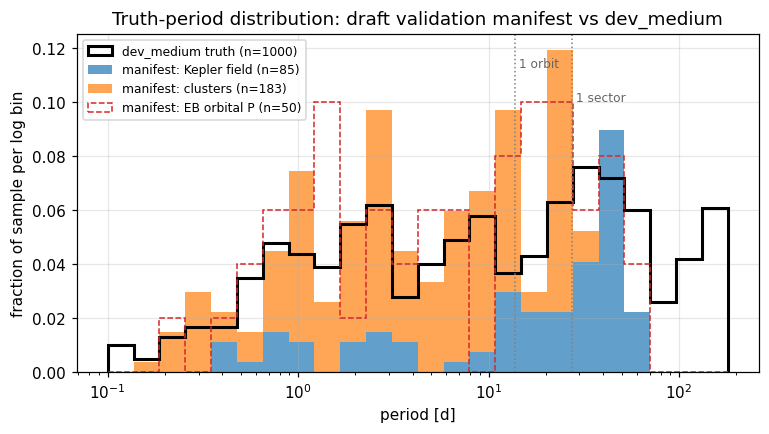

truth_period
(0.1, 1.0]      48
(1.0, 3.0]      48
(3.0, 10.0]     48
(10.0, 20.0]    48
(20.0, 40.0]    48
(40.0, 71.0]    28
Name: count, dtype: int64


In [4]:
bins = np.logspace(np.log10(0.1), np.log10(180), 25)
fig, ax = plt.subplots(figsize=(8, 4))
frac = lambda x, n: np.full(len(x), 1.0 / n)
ax.hist(dev.true_period, bins=bins, histtype="step", lw=2, color="k", weights=frac(dev, len(dev)),
        label=f"dev_medium truth (n={len(dev)})")
r = man[man.label == "rotator"]
kf, cl = r[r.source == "Kepler-field"].truth_period, r[r.source != "Kepler-field"].truth_period
ax.hist([kf, cl], bins=bins, stacked=True, weights=[frac(kf, len(r)), frac(cl, len(r))], alpha=0.7,
        label=[f"manifest: Kepler field (n={len(kf)})", f"manifest: clusters (n={len(cl)})"])
eb = man[man.label == "contaminant_eb"]
ax.hist(eb.truth_period, bins=bins, histtype="step", ls="--", color="C3", weights=frac(eb, len(eb)),
        label=f"manifest: EB orbital P (n={len(eb)})")
for p in (13.7, 27.4):
    ax.axvline(p, color="0.5", ls=":", lw=1)
ax.text(13.7, ax.get_ylim()[1]*0.9, " 1 orbit", fontsize=8, color="0.4"); ax.text(27.4, ax.get_ylim()[1]*0.8, " 1 sector", fontsize=8, color="0.4")
ax.set_xscale("log"); ax.set_xlabel("period [d]"); ax.set_ylabel("fraction of sample per log bin"); ax.legend(fontsize=8)
ax.set_title("Truth-period distribution: draft validation manifest vs dev_medium")
fig.savefig(FIG / "period_distribution_vs_dev_medium.png"); plt.show()
print(pd.cut(r.truth_period, [0.1,1,3,10,20,40,71]).value_counts().sort_index())

## 4. Tmag distribution per source (draft manifest)

/var/folders/kk/_9cq7r5j5nd8cxryt5p59v2c0000gn/T/ipykernel_9162/2013257635.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([man[man.source == s].Tmag.dropna() for s in srcs], vert=False, labels=[f"{s} ({(man.source==s).sum()})" for s in srcs])


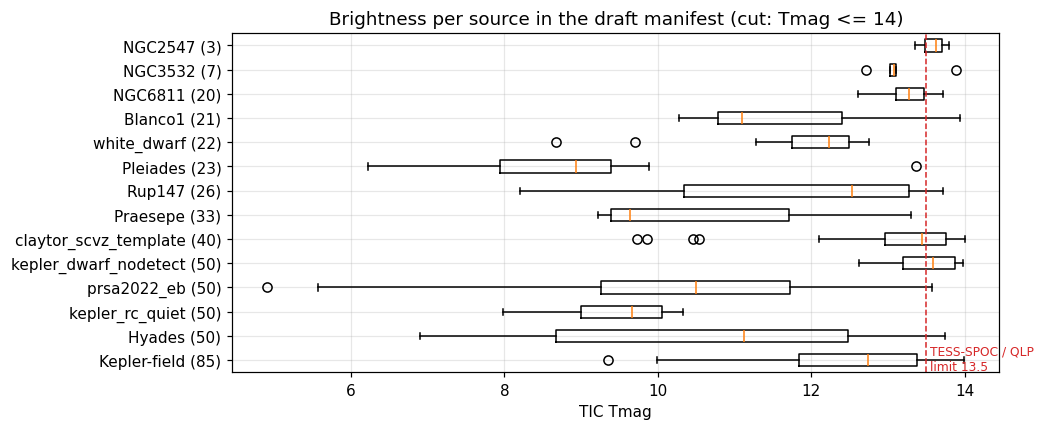

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
srcs = man.source.value_counts().index
ax.boxplot([man[man.source == s].Tmag.dropna() for s in srcs], vert=False, labels=[f"{s} ({(man.source==s).sum()})" for s in srcs])
ax.axvline(13.5, color="C3", ls="--", lw=1); ax.text(13.55, 0.6, "TESS-SPOC / QLP\nlimit 13.5", color="C3", fontsize=8)
ax.set_xlabel("TIC Tmag"); ax.set_title("Brightness per source in the draft manifest (cut: Tmag <= 14)")
fig.savefig(FIG / "tmag_per_source.png"); plt.show()

## 5. Sector counts and light-curve product availability

Left: number of TESS FFI sectors (TESScut) per star, by label. Right: fraction of manifest stars with at least one sector of each HLSP product at MAST, and median sectors per product.

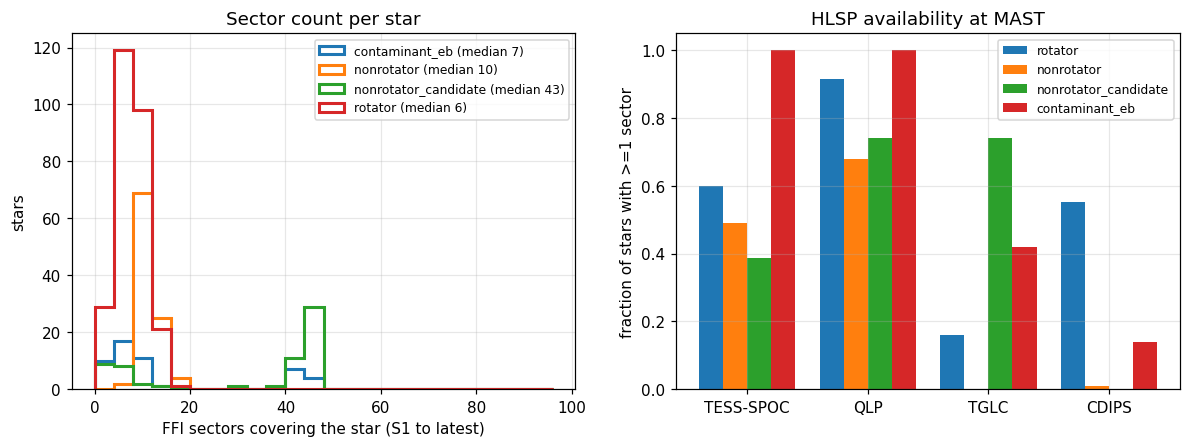

                      n_sectors  n_tess_spoc  n_qlp  n_tglc  n_cdips
label                                                               
contaminant_eb              7.0          5.0    6.5     0.0      0.0
nonrotator                 10.0          0.0    8.0     0.0      0.0
nonrotator_candidate       43.0          0.0    6.5    10.0      0.0
rotator                     6.0          3.0    4.0     0.0      2.0
                      n_tess_spoc  n_qlp  n_tglc  n_cdips
label                                                    
contaminant_eb               1.00   1.00    0.42     0.14
nonrotator                   0.49   0.68    0.00     0.01
nonrotator_candidate         0.39   0.74    0.74     0.00
rotator                      0.60   0.91    0.16     0.55


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
for lab, g in man.groupby("label"):
    ax.hist(g.n_sectors, bins=np.arange(0, 100, 4), histtype="step", lw=2, label=f"{lab} (median {g.n_sectors.median():.0f})")
ax.set_xlabel("FFI sectors covering the star (S1 to latest)"); ax.set_ylabel("stars"); ax.legend(fontsize=8)
ax.set_title("Sector count per star")
ax = axes[1]
prods = ["n_tess_spoc", "n_qlp", "n_tglc", "n_cdips"]
labs = man.label.unique()
w = 0.8 / len(labs)
for i, lab in enumerate(labs):
    g = man[man.label == lab]
    ax.bar(np.arange(len(prods)) + i * w, [(g[p] > 0).mean() for p in prods], width=w, label=lab)
ax.set_xticks(np.arange(len(prods)) + 0.4 - w / 2); ax.set_xticklabels([p[2:].upper().replace("_", "-") for p in prods])
ax.set_ylabel("fraction of stars with >=1 sector"); ax.set_ylim(0, 1.05); ax.legend(fontsize=8)
ax.set_title("HLSP availability at MAST")
fig.savefig(FIG / "sectors_and_products.png"); plt.show()
print(man.groupby("label")[["n_sectors"] + prods].median())
print(man.groupby("label")[prods].apply(lambda d: (d > 0).mean()).round(2))

## 6. Non-rotator source pools and counts

Pool sizes (log scale) per candidate non-rotator source at TESS-usable brightness, from `data/nonrotator_pools.csv`.

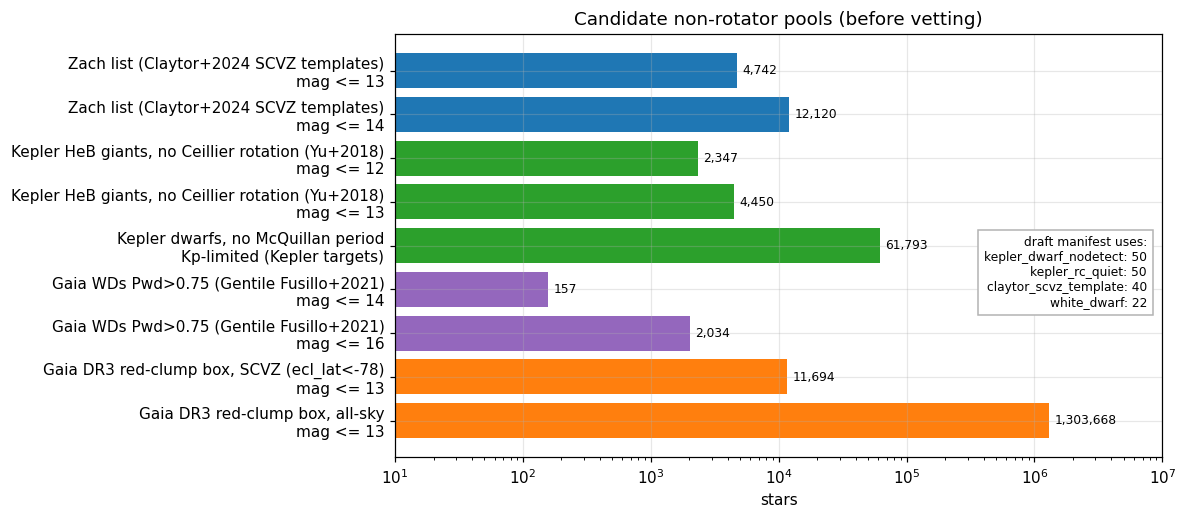

In [7]:
pools = pd.read_csv(DATA / "nonrotator_pools.csv")
pick = [("Zach list (Claytor+2024 SCVZ templates)", 13), ("Zach list (Claytor+2024 SCVZ templates)", 14),
        ("Kepler HeB giants, no Ceillier rotation (Yu+2018)", 12), ("Kepler HeB giants, no Ceillier rotation (Yu+2018)", 13),
        ("Kepler dwarfs, no McQuillan period", np.nan),
        ("Gaia WDs Pwd>0.75 (Gentile Fusillo+2021)", 14), ("Gaia WDs Pwd>0.75 (Gentile Fusillo+2021)", 16),
        ("Gaia DR3 red-clump box, SCVZ (ecl_lat<-78)", 13), ("Gaia DR3 red-clump box, all-sky", 13)]
rows = []
for s, t in pick:
    m = pools[(pools.source == s) & ((pools.tmag_max == t) | (pd.isna(t) & pools.tmag_max.isna()))]
    rows.append((f"{s}\n" + (f"mag <= {t:g}" if not pd.isna(t) else "Kp-limited (Kepler targets)"), int(m.n.iloc[0])))
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([r[0] for r in rows], [r[1] for r in rows], color=["C0","C0","C2","C2","C2","C4","C4","C1","C1"])
for i, r in enumerate(rows):
    ax.text(r[1] * 1.1, i, f"{r[1]:,}", va="center", fontsize=8)
ax.set_xscale("log"); ax.set_xlim(10, 1e7); ax.invert_yaxis(); ax.set_xlabel("stars")
ax.set_title("Candidate non-rotator pools (before vetting)")
used = man[man.label.str.startswith("nonrot")].source.value_counts()
ax.text(0.98, 0.35, "draft manifest uses:\n" + "\n".join(f"{k}: {v}" for k, v in used.items()), transform=ax.transAxes,
        ha="right", va="bottom", fontsize=8, bbox=dict(fc="w", ec="0.7"))
fig.savefig(FIG / "nonrotator_pools.png"); plt.show()

## 7. Zach's list: what the stars are

TIC v8.2 properties of all 23,332 TIC IDs, compared with the Claytor+2024 noise-template cuts (Teff 5800-6000 K, Tmag 6-15, ecliptic latitude <= -78 deg). Right: Kepler detection fraction vs Teff from McQuillan+2014, showing that ~14% of Kepler stars in this Teff range do show rotation.

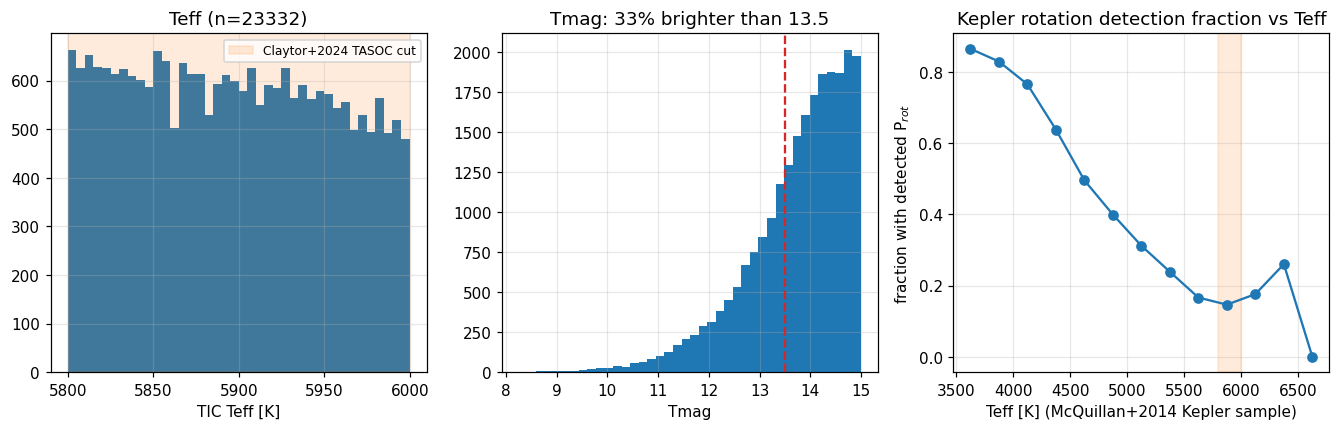

           Teff      Tmag      logg
count  23332.00  23332.00  23331.00
mean    5896.19     13.73      4.33
std       56.91      1.01      0.16
min     5800.04      8.26      3.99
25%     5847.00     13.21      4.20
50%     5895.00     13.96      4.33
75%     5944.16     14.50      4.45
max     5999.91     15.00      4.99


In [8]:
z = pd.read_csv(DATA / "zach_list_tic.csv.gz")
dfrac = pd.read_csv(DATA / "mcquillan_detfrac.csv")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(z.Teff, bins=40); axes[0].axvspan(5800, 6000, color="C1", alpha=0.15, label="Claytor+2024 TASOC cut")
axes[0].set_xlabel("TIC Teff [K]"); axes[0].legend(fontsize=8); axes[0].set_title(f"Teff (n={len(z)})")
axes[1].hist(z.Tmag, bins=40); axes[1].axvline(13.5, color="C3", ls="--"); axes[1].set_xlabel("Tmag")
axes[1].set_title(f"Tmag: {(z.Tmag<=13.5).mean():.0%} brighter than 13.5")
ax = axes[2]
mid = 0.5 * (dfrac.teff_lo + dfrac.teff_hi)
ax.plot(mid, dfrac.frac, "o-"); ax.axvspan(5800, 6000, color="C1", alpha=0.15)
ax.set_xlabel("Teff [K] (McQuillan+2014 Kepler sample)"); ax.set_ylabel("fraction with detected P$_{rot}$")
ax.set_title("Kepler rotation detection fraction vs Teff")
fig.savefig(FIG / "zach_list_properties.png"); plt.show()
print(z[["Teff","Tmag","logg"]].describe().round(2))